           Model Train data  MAE  RMSE  MAPE %
         XGBoost        raw 3.88  4.70   22.60
         XGBoost   filtered 4.28  5.38   25.05
SARIMA (d=0,D=1)        raw 4.59  5.54   30.28
    Holt-Winters        raw 4.67  5.66   31.01
SARIMA (d=0,D=1)   filtered 4.90  6.11   32.68
SARIMA (d=1,D=1)        raw 4.92  6.06   33.23
    Holt-Winters   filtered 5.06  6.29   34.01
  Seasonal naive   filtered 5.28  6.56   35.83
SARIMA (d=1,D=1)   filtered 5.46  6.74   37.29
  Seasonal naive        raw 6.46  7.76   39.13

Best per model:
            Model Train data  MAE  RMSE  MAPE %
         XGBoost        raw 3.88  4.70   22.60
SARIMA (d=0,D=1)        raw 4.59  5.54   30.28
    Holt-Winters        raw 4.67  5.66   31.01
SARIMA (d=1,D=1)        raw 4.92  6.06   33.23
  Seasonal naive   filtered 5.28  6.56   35.83


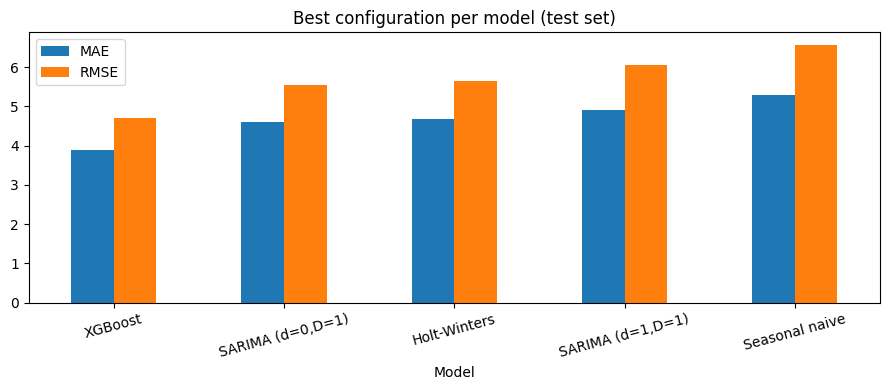

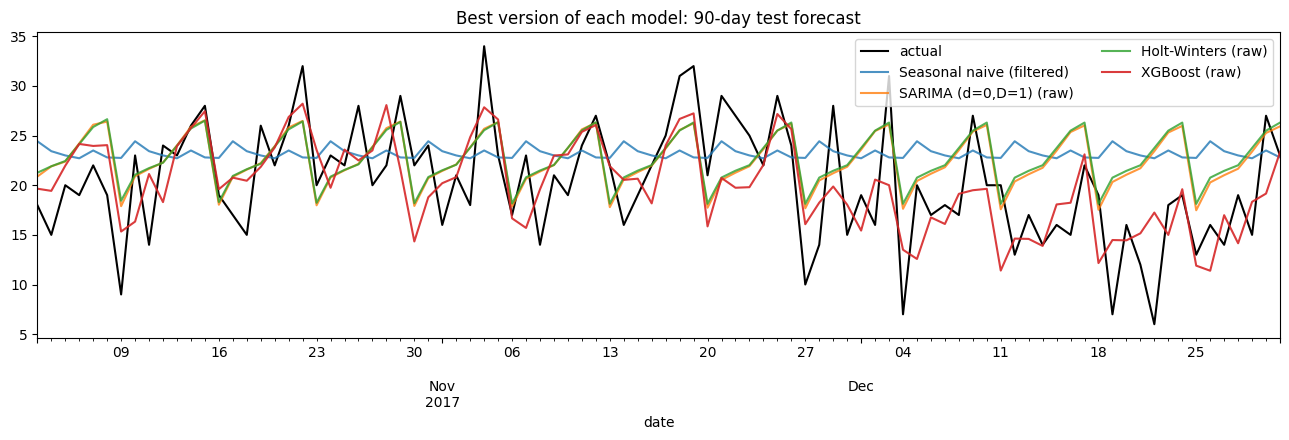

In [1]:
import pandas as pd, matplotlib.pyplot as plt

res = pd.concat([pd.read_csv("../outputs/results_traditional.csv"),
                 pd.read_csv("../outputs/results_xgb.csv")], ignore_index=True)
res = res.sort_values("MAPE %").reset_index(drop=True)
print(res.to_string(index=False))
res.to_csv("../outputs/results_all.csv", index=False)

# best configuration per model
best = res.loc[res.groupby("Model")["MAE"].idxmin()].sort_values("MAE")
print("\nBest per model:\n", best.to_string(index=False))

# bar chart of best per model
best.set_index("Model")[["MAE", "RMSE"]].plot.bar(figsize=(9, 4), rot=15,
                                                  title="Best configuration per model (test set)")
plt.tight_layout(); plt.savefig("../outputs/06_model_comparison.png", dpi=150)

# forecast overlay
test = pd.read_csv("../data/test_raw.csv", parse_dates=["date"], index_col="date")["sales"]
pt = pd.read_csv("../outputs/preds_traditional.csv", parse_dates=["date"], index_col="date")
px = pd.read_csv("../outputs/preds_xgb.csv", parse_dates=["date"], index_col="date")

fig, ax = plt.subplots(figsize=(13, 4.5))
test.plot(ax=ax, color="black", lw=1.5, label="actual")
for col in ["Seasonal naive (filtered)", "SARIMA (d=0,D=1) (raw)", "Holt-Winters (raw)"]:
    pt[col].plot(ax=ax, alpha=0.8, label=col)
px["XGBoost (raw)"].plot(ax=ax, alpha=0.9, label="XGBoost (raw)")
ax.legend(ncol=2); ax.set_title("Best version of each model: 90-day test forecast")
plt.tight_layout(); plt.savefig("../outputs/06_forecast_overlay.png", dpi=150)

           Model Train data  MAE  RMSE  MAPE %
            LSTM        raw 3.88  4.66   24.32
         XGBoost        raw 3.88  4.70   22.60
            LSTM   filtered 4.25  5.46   26.65
         XGBoost   filtered 4.28  5.38   25.05
SARIMA (d=0,D=1)        raw 4.59  5.54   30.28
    Holt-Winters        raw 4.67  5.66   31.01
SARIMA (d=0,D=1)   filtered 4.90  6.11   32.68
SARIMA (d=1,D=1)        raw 4.92  6.06   33.23
    Holt-Winters   filtered 5.06  6.29   34.01
  Seasonal naive   filtered 5.28  6.56   35.83
SARIMA (d=1,D=1)   filtered 5.46  6.74   37.29
  Seasonal naive        raw 6.46  7.76   39.13

Best per model:
            Model Train data  MAE  RMSE  MAPE %
            LSTM        raw 3.88  4.66   24.32
         XGBoost        raw 3.88  4.70   22.60
SARIMA (d=0,D=1)        raw 4.59  5.54   30.28
    Holt-Winters        raw 4.67  5.66   31.01
SARIMA (d=1,D=1)        raw 4.92  6.06   33.23
  Seasonal naive   filtered 5.28  6.56   35.83

MAE by training data (positive = filterin

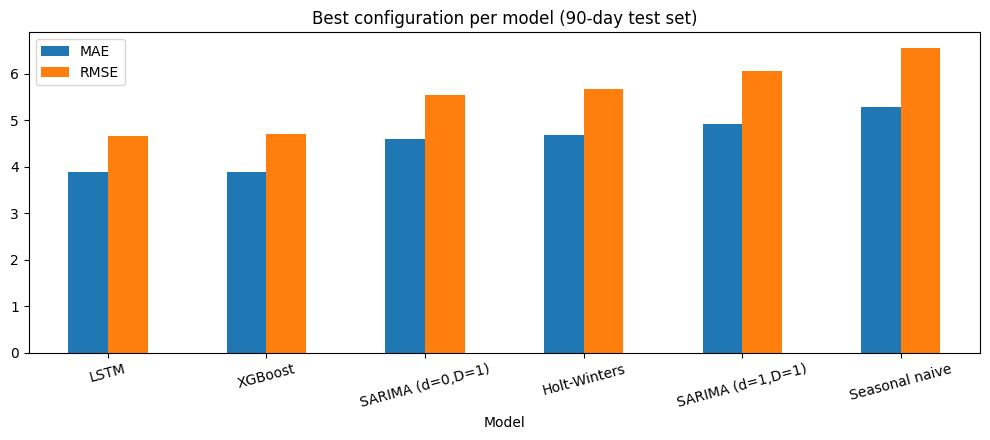

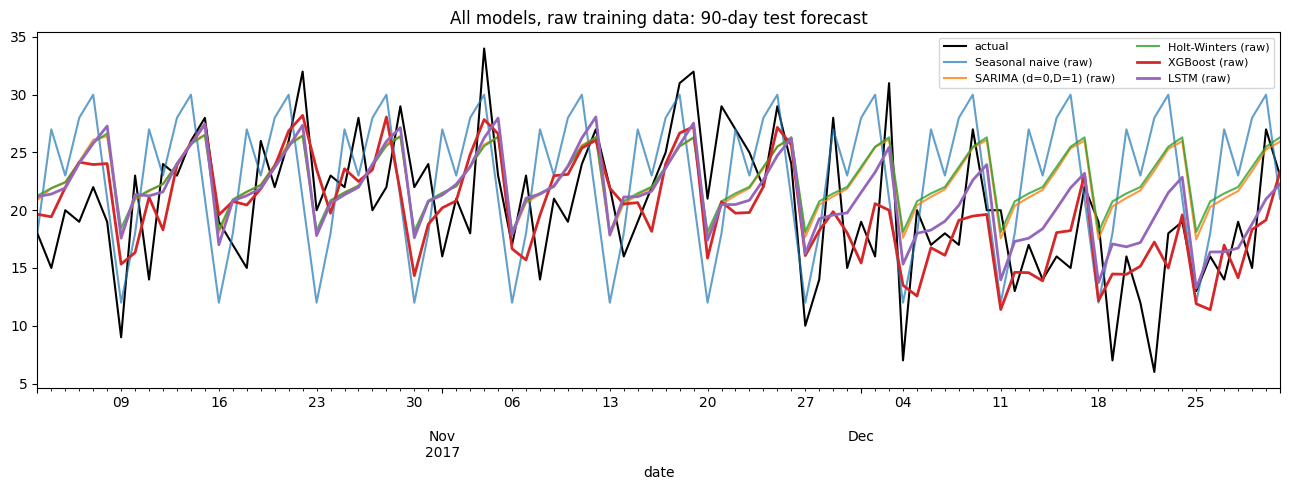

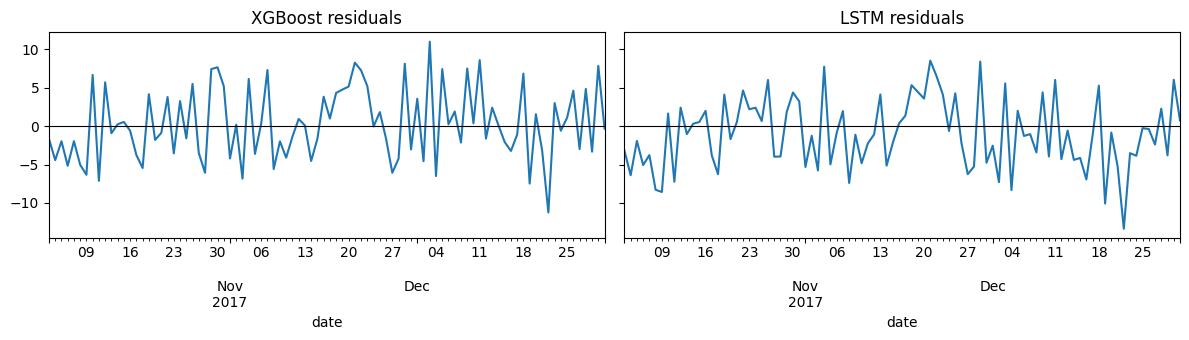

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

res = pd.concat([pd.read_csv("../outputs/results_traditional.csv"),
                 pd.read_csv("../outputs/results_xgb.csv"),
                 pd.read_csv("../outputs/results_lstm.csv")], ignore_index=True)
res = res.sort_values("MAE").reset_index(drop=True)
print(res.to_string(index=False))
res.to_csv("../outputs/results_all.csv", index=False)

# best configuration per model
best = res.loc[res.groupby("Model")["MAE"].idxmin()].sort_values("MAE").reset_index(drop=True)
print("\nBest per model:\n", best.to_string(index=False))
best.to_csv("../outputs/results_best_per_model.csv", index=False)

# bar chart: best per model
best.set_index("Model")[["MAE", "RMSE"]].plot.bar(figsize=(10, 4.5), rot=15,
        title="Best configuration per model (90-day test set)")
plt.tight_layout(); plt.savefig("../outputs/06_model_comparison.png", dpi=150)

# raw vs filtered effect (for the report)
pivot = res.pivot_table(index="Model", columns="Train data", values="MAE")
pivot["filtering effect"] = pivot["filtered"] - pivot["raw"]
print("\nMAE by training data (positive = filtering hurt):\n", pivot.round(2))
pivot.to_csv("../outputs/filtering_effect.csv")

# forecast overlay
test = pd.read_csv("../data/test_raw.csv", parse_dates=["date"], index_col="date")["sales"]
pt = pd.read_csv("../outputs/preds_traditional.csv", parse_dates=["date"], index_col="date")
px = pd.read_csv("../outputs/preds_xgb.csv", parse_dates=["date"], index_col="date")
pl = pd.read_csv("../outputs/preds_lstm.csv", parse_dates=["date"], index_col="date")

fig, ax = plt.subplots(figsize=(13, 5))
test.plot(ax=ax, color="black", lw=1.5, label="actual")
pt["Seasonal naive (raw)"].plot(ax=ax, alpha=0.7, label="Seasonal naive (raw)")
pt["SARIMA (d=0,D=1) (raw)"].plot(ax=ax, alpha=0.8, label="SARIMA (d=0,D=1) (raw)")
pt["Holt-Winters (raw)"].plot(ax=ax, alpha=0.8, label="Holt-Winters (raw)")
px["XGBoost (raw)"].plot(ax=ax, lw=2, label="XGBoost (raw)")
pl["LSTM (raw)"].plot(ax=ax, lw=2, label="LSTM (raw)")
ax.legend(ncol=2, fontsize=8); ax.set_title("All models, raw training data: 90-day test forecast")
plt.tight_layout(); plt.savefig("../outputs/06_forecast_overlay.png", dpi=150)

# residuals of the two best models
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
(test - px["XGBoost (raw)"]).plot(ax=ax[0], title="XGBoost residuals")
(test - pl["LSTM (raw)"]).plot(ax=ax[1], title="LSTM residuals")
for a in ax: a.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.savefig("../outputs/06_residuals.png", dpi=150)